# 3일차 21코드 Jupyter 리뷰 — src/21_cap_rule.py

교재: `3일차 — 21코드 Jupyter로 코드 리뷰 방법.md`

- 이 노트북은 **프로젝트 최상위 폴더**에 둡니다.
- 위에서 아래로 `Shift+Enter`로 실행하고, 최종 확인은 **Kernel 재시작 후 전체 실행**.
- 단축키: `Esc`→`B`/`A` 셀 추가 · `Esc`→`Y`/`M` 코드/Markdown · `Esc`→`D` `D` 삭제 · `Esc`→`0` `0` 커널 재시작

## 오늘 완성할 파일과 폴더

```text
subject9_machinevision/
├── samples/
│   └── day03/
│       └── reference/
│           ├── cap_on.jpg          ← 병뚜껑 있음: 1·2일차에 이어지는 ROI
│           └── cap_off.jpg         ← 병뚜껑 없음: 1·2일차에 이어지는 ROI
├── src/
│   └── 21_cap_rule.py              ← 기존 전체 실행 프로그램
└── outputs/
    └── day03/
        └── rule/
            ├── cap_on_rule.jpg     ← Contour + OK + Area Ratio
            └── cap_off_rule.jpg    ← Contour + NG + Area Ratio
```

**데이터 준비:** 두 입력 이미지는 이미 ROI로 잘려 있으므로 **다시 ROI를 자르지 않습니다.** 3일차 `cap_on_001.jpg`~`cap_on_003.jpg`, `cap_off_001.jpg`~`cap_off_003.jpg`는 **다음 `22_cap_batch_test.py` 실습에 사용**합니다. 이번 21번 실습에는 위 `reference` 폴더의 두 장만 필요합니다.

**시작하기 전에:** VS Code에서 `subject9_machinevision` 폴더를 열고 해당 프로젝트의 Python 가상환경을 Jupyter Kernel로 선택합니다. 파일 경로는 모두 **프로젝트 최상위 폴더에서 실행하는 상대경로**입니다.

**Jupyter 실행 원칙**

- 아래의 **Python 코드 블록 하나가 Jupyter Code Cell 하나**입니다. 순서대로 복사하고 `Shift + Enter`로 실행합니다.
- `# BLOCK` 및 `# STEP`은 설명용 주석으로 실행에 영향을 주지 않습니다.
- 실행 결과는 **미리 정해진 숫자를 외우는 것이 아니라 실제 이미지에서 나온 값**으로 확인합니다.
- `matplotlib`을 이용한 시각화, 픽셀·배열 확인, 변경 전후 비교는 **Jupyter 학습용 추가 코드**입니다.
- 원본 프로그램의 `def measure_area_ratio(...)`와 `def judge_cap(...)` 정의는 **각각 하나의 셀**로 완성해야 합니다. 함수의 들여쓰기 본문을 여러 셀에 나누면 Python 문법 오류가 발생하므로, 함수를 정의하기 전에 같은 연산을 작은 셀로 먼저 충분히 검증합니다.
- 실습을 마치면 **Kernel 재시작 → 전체 셀 순서대로 실행**하여 변수 누락 없이 재현되는지 확인합니다.
- 이 실습에서 저장하는 결과는 원본 `.py`와 같은 경로를 사용하므로, 둘 중 하나를 다시 실행하면 **결과 이미지가 덮어써질 수 있습니다**.

## 처음부터 끝까지의 흐름

```text
[INPUT — 입력·검증]
cap_on.jpg / cap_off.jpg 경로 확인
        ↓
cap_on.jpg를 먼저 한 장씩 분석
        ↓
[PROCESS — 영상처리]
BGR → Gray → Otsu(Binary Inverse)
        ↓
Morphology: Opening → Closing
        ↓
[FEATURE — 객체 측정]
Contour 찾기 → 작은 Contour 제외
        ↓
가장 큰 Contour의 Area 계산
        ↓
Area Ratio = Contour Area / ROI 전체 면적
        ↓
[COMPARE — 실제 측정값 비교]
measure_area_ratio() 함수로 두 이미지 측정
        ↓
cap_on_ratio / cap_off_ratio 비교
        ↓
[RULE — 기준값 생성·판정]
두 비율의 중간값 = candidate_threshold
        ↓
어느 쪽 비율이 큰지 확인
        ↓
judge_cap() → OK 또는 NG
        ↓
[OUTPUT — 시각화·검증]
녹색 Contour + OK/NG + ratio 표시
        ↓
cap_on_rule.jpg / cap_off_rule.jpg 저장
        ↓
원본 src/21_cap_rule.py 재실행·결과 확인
```

## 블록 안내

| BLOCK | 분류 | 검증할 핵심 질문 |
|---|---|---|
| 1 | 입력·설정 | 두 이미지가 실제로 존재하고 저장 경로가 맞는가? |
| 2 | 이미지 분석 | BGR, Gray, Shape와 픽셀값을 이해했는가? |
| 3 | Otsu / Binary | 어두운 부분이 왜 흰색(255)으로 변하는가? |
| 4 | Morphology | Opening·Closing 전후 무엇이 달라지는가? |
| 5 | Contour / Feature | 가장 큰 Contour와 Area Ratio는 어떻게 계산되는가? |
| 6 | 함수 통합·두 이미지 비교 | 동일한 측정 함수를 `cap_on` / `cap_off`에 적용하는가? |
| 7 | 기준값·Rule | 기준값을 어떻게 만들고 OK / NG를 구분하는가? |
| 8 | 이미지 표시·저장 | 원본을 보존하며 Contour와 판정을 표시하는가? |
| 9 | 원본 코드 연결·Challenge | Jupyter 결과를 원본 프로그램에서 재현할 수 있는가? |

### 한눈에 보는 의사코드

```text
1. cap_on / cap_off 기준 이미지 경로를 정한다.
2. 이미지가 존재하는지 확인한다.
3. cap_on 이미지를 읽고 Gray로 변환한다.
4. Otsu + THRESH_BINARY_INV로 어두운 영역을 흰색 객체로 만든다.
5. 3×3 타원형 Kernel로 Opening, Closing을 한 번씩 실행한다.
6. 정리된 Binary에서 Contour를 찾는다.
7. ROI 전체 면적의 0.1%보다 작은 Contour를 제외한다.
8. 가장 큰 Contour를 선택한다.
9. Area Ratio = 가장 큰 Contour의 면적 / ROI 전체 면적을 계산한다.
10. 위 작업을 함수로 만들고 cap_on / cap_off를 각각 측정한다.
11. 두 비율의 중간값을 후보 기준값으로 정한다.
12. cap_on의 비율이 더 큰지 비교 방향을 확인한다.
13. 새 Area Ratio를 기준값과 비교해 OK 또는 NG를 반환한다.
14. 원본 이미지 복사본에 Contour·판정·비율을 표시한다.
15. 두 결과 이미지를 저장한 뒤 다시 읽어 확인한다.
```

---

# BLOCK 1 — 이미지 경로와 실습환경 확인(Input + Setting)

## STEP 1. 필요한 라이브러리를 가져옵니다

In [1]:
### BLOCK 1 — 입력과 설정
### STEP 1: 라이브러리 준비
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt  # Jupyter 화면 확인용(추가)

`Path`는 파일 경로를 관리하고 `cv2`는 영상을 처리합니다. `numpy`는 원본 21번 코드에도 import되어 있지만 **원본 계산 자체에서는 직접 사용하지 않습니다.** 이 리뷰에서는 배열·픽셀 검증에 이용합니다. `plt`는 Jupyter에서 결과를 눈으로 확인하기 위해 추가했습니다.

## STEP 2. 현재 작업 폴더를 확인합니다

In [2]:
### STEP 2: 상대경로 기준
print("현재 작업 폴더:", Path.cwd())

현재 작업 폴더: /home/user1/ai_vision/subject9_machinevision


`.../subject9_machinevision`이 표시되어야 합니다. 다르면 **이미지가 있는데도 파일을 찾지 못하는 문제**가 생깁니다.

## STEP 3. 사용할 기준 이미지의 경로를 지정합니다

In [3]:
### STEP 3: 입력 파일 경로
CAP_ON_PATH = Path("samples/day03/reference/cap_on.jpg")
CAP_OFF_PATH = Path("samples/day03/reference/cap_off.jpg")
print("ON :", CAP_ON_PATH)
print("OFF:", CAP_OFF_PATH)

ON : samples/day03/reference/cap_on.jpg
OFF: samples/day03/reference/cap_off.jpg


지금은 경로를 정한 단계이고 실제 이미지를 읽지는 않았습니다.

## STEP 4. 파일이 실제로 존재하는지 확인합니다

In [4]:
### STEP 4: 두 파일의 존재 확인
print("ON 파일 존재 :", CAP_ON_PATH.is_file())
print("OFF 파일 존재:", CAP_OFF_PATH.is_file())

ON 파일 존재 : True
OFF 파일 존재: True


정상이라면 둘 다 `True`입니다. `False`라면 현재 폴더와 `samples/day03/reference`의 파일명을 먼저 확인합니다.

## STEP 5. 결과 저장 경로를 정합니다

In [5]:
### STEP 5: 출력 경로 지정
OUTPUT_DIR = Path("outputs/day03/rule")
print("출력 폴더:", OUTPUT_DIR)

출력 폴더: outputs/day03/rule


여기까지는 경로 지정만 했습니다.

## STEP 6. 출력 폴더를 만듭니다

In [6]:
### STEP 6: 출력 폴더 생성
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("폴더 생성 확인:", OUTPUT_DIR.is_dir())

폴더 생성 확인: True


`parents=True`는 상위 폴더도 필요하면 만들고, `exist_ok=True`는 이미 폴더가 있어도 오류를 내지 않도록 합니다.

## STEP 7. 작은 Contour를 제외할 기준을 정합니다

In [7]:
### STEP 7: 작은 영역 제외 기준
MIN_CONTOUR_AREA_RATIO = 0.001
print("최소 Contour 비율:", MIN_CONTOUR_AREA_RATIO)
print("백분율:", MIN_CONTOUR_AREA_RATIO * 100, "%")

최소 Contour 비율: 0.001
백분율: 0.1 %


`0.001`은 **ROI 전체 면적의 0.1%**라는 뜻입니다. 이것은 마지막 OK/NG 기준값이 아닙니다. **작은 Contour를 제외하는 기준**일 뿐입니다.

---

# BLOCK 2 — 이미지 읽기와 Gray 변환(Input Analysis)

> 이 블록부터 `cap_on.jpg` 한 장을 먼저 세부 분석합니다. 이후 같은 절차를 함수로 만들어 `cap_off.jpg`에도 적용합니다.

## STEP 8. 병뚜껑이 있는 이미지를 읽습니다

In [8]:
### BLOCK 2 — 기준 이미지 분석
### STEP 8: cap_on 이미지 입력
image = cv2.imread(str(CAP_ON_PATH))
print("읽기 결과 자료형:", type(image))

읽기 결과 자료형: <class 'numpy.ndarray'>


정상적으로 읽으면 `numpy.ndarray`입니다. 읽기 실패 시 `None`이 나올 수 있습니다.

## STEP 9. 이미지 읽기 오류를 검사합니다

In [9]:
### STEP 9: 입력 오류 확인
if image is None:
    raise FileNotFoundError(f"기준 이미지를 읽지 못했습니다: {CAP_ON_PATH}")
print("cap_on 이미지 읽기 성공")

cap_on 이미지 읽기 성공


`is_file()`이 `True`라도 파일이 손상되면 `imread()`가 실패할 수 있으므로 별도로 검사합니다.

## STEP 10. 이미지의 배열 크기와 한 픽셀을 확인합니다

In [10]:
### STEP 10: BGR 데이터 구조
print("Shape:", image.shape)
print("Dtype:", image.dtype)
print("첫 픽셀 BGR:", image[0, 0])

Shape: (198, 213, 3)
Dtype: uint8
첫 픽셀 BGR: [190 185 186]


컬러 이미지 Shape는 `(세로, 가로, 채널 수)`입니다. OpenCV의 컬러 채널 순서는 **BGR**입니다. 픽셀값은 사진마다 다릅니다.

## STEP 11. 원본 이미지를 화면에서 확인합니다

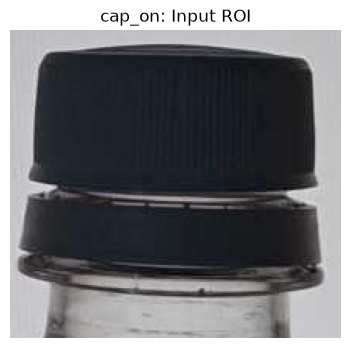

In [11]:
### STEP 11: 원본 BGR → 화면 표시용 RGB
plt.figure(figsize=(5, 4))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("cap_on: Input ROI")
plt.axis("off")
plt.show()

**확인:** 이미지에 병뚜껑 전체가 들어 있나요? 이미 ROI로 잘렸으므로 여기서 다시 `image[y1:y2, x1:x2]`를 하지 않습니다.

## STEP 12. Gray로 변환합니다

In [12]:
### STEP 12: BGR → Gray
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print("Gray Shape:", gray.shape)

Gray Shape: (198, 213)


컬러의 `(높이, 너비, 3)`이 단일 채널인 `(높이, 너비)`가 됩니다. **3가지 색 채널에서 밝기 정보 중심의 한 가지 값으로 바꾸는 작업**입니다.

## STEP 13. Gray 배열의 픽셀값을 직접 확인합니다

In [13]:
### STEP 13: Gray 픽셀값
h, w = gray.shape
sample_y, sample_x = h // 2, w // 2
print("중앙 좌표 (x,y):", (sample_x, sample_y))
print("중앙 BGR:", image[sample_y, sample_x])
print("중앙 Gray:", gray[sample_y, sample_x])

중앙 좌표 (x,y): (106, 99)
중앙 BGR: [38 29 25]
중앙 Gray: 29


`Gray` 값은 일반적으로 0(검정)~255(흰색)입니다. **아직 Binary가 아니므로 0과 255 외의 숫자도 나옵니다.**

## STEP 14. Gray 이미지를 시각화합니다

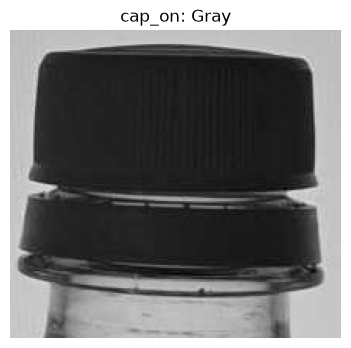

In [14]:
### STEP 14: Gray 화면 출력
plt.figure(figsize=(5, 4))
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("cap_on: Gray")
plt.axis("off")
plt.show()

**확인 질문:** 검은 병뚜껑과 밝은 병목·배경에서 Gray 값이 다르게 나타나나요?

---

# BLOCK 3 — Otsu / Binary를 픽셀값으로 검증(Processing ①)

## STEP 15. Otsu Threshold를 적용합니다

In [15]:
### BLOCK 3 — Otsu Binary
### STEP 15: Otsu + 역이진화
otsu_value, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU,
)
print("Otsu가 선택한 임계값:", otsu_value)

Otsu가 선택한 임계값: 111.0


`THRESH_OTSU`가 이미지 밝기 분포를 이용하여 임계값을 자동으로 고릅니다. `THRESH_BINARY_INV`는 이 기준을 사용해 **어두운 픽셀을 255(흰색), 밝은 픽셀을 0(검정)** 으로 변환합니다. 원본의 `0` 인수는 Otsu가 임계값을 선택하기 때문에 고정 기준값으로 사용되지 않습니다.

## STEP 16. Binary 이미지의 픽셀값 종류를 확인합니다

In [16]:
### STEP 16: Binary 고유 값 확인
print("Binary Shape:", binary.shape)
print("Binary 값 종류:", np.unique(binary))

Binary Shape: (198, 213)
Binary 값 종류: [  0 255]


정상적인 이진화 결과라면 실제 이미지 상태에 따라 **0과 255 중 하나 또는 둘 다** 나타납니다. 새로운 자료형의 파일로 바꾼 것이 아니라 **기존 이미지 배열의 픽셀값을 변환한 것**입니다.

## STEP 17. 특정 픽셀이 왜 0 또는 255가 됐는지 계산해 봅니다

In [17]:
### STEP 17: 한 픽셀의 역이진화 논리 검증
pixel_gray = int(gray[sample_y, sample_x])
pixel_binary = int(binary[sample_y, sample_x])
expected_binary = 255 if pixel_gray <= otsu_value else 0
print("Gray 값:", pixel_gray)
print("Otsu 기준:", otsu_value)
print("실제 Binary 값:", pixel_binary)
print("규칙으로 계산한 값:", expected_binary)
print("일치 여부:", pixel_binary == expected_binary)

Gray 값: 29
Otsu 기준: 111.0
실제 Binary 값: 255
규칙으로 계산한 값: 255
일치 여부: True


`THRESH_BINARY_INV`에서 **Gray ≤ Otsu 임계값이면 255**, 더 크면 0이 됩니다. 원리가 이해되면 `sample_x`, `sample_y`를 이미지 안의 다른 위치로 바꿔 다시 확인해 보세요.

## STEP 18. Binary 이미지를 화면에 출력합니다

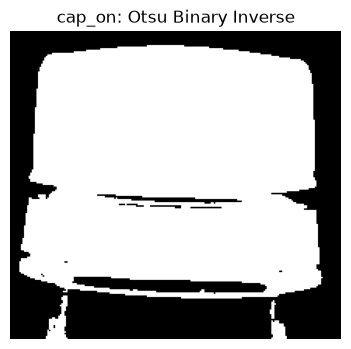

In [18]:
### STEP 18: 흑백 분리 결과
plt.figure(figsize=(5, 4))
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("cap_on: Otsu Binary Inverse")
plt.axis("off")
plt.show()

**확인:** 어두운 병뚜껑 부위가 흰색 영역으로 나타나나요? 작은 흰 점이나 흰색 영역 안의 작은 검정 구멍은 없나요?

## STEP 19. Gray와 Binary를 나란히 비교합니다(Jupyter 추가)

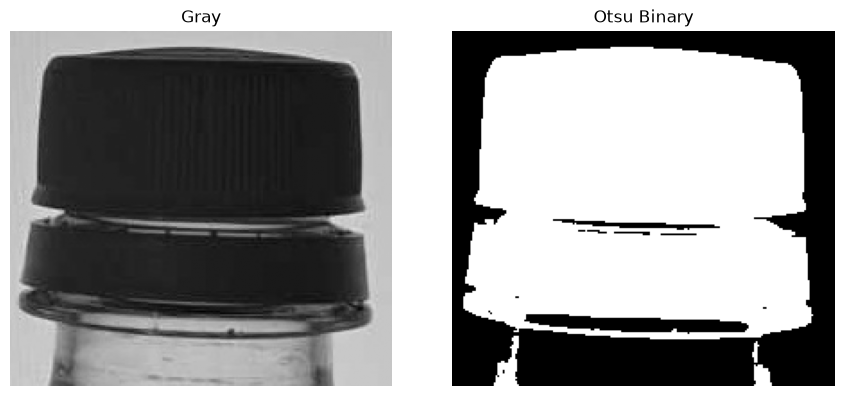

In [19]:
### STEP 19: Gray vs Binary
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Gray")
axes[1].imshow(binary, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Otsu Binary")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**핵심:** 2일차에서 학습한 **이진화 결과가 바로 3일차 Morphology와 Contour 측정의 입력**입니다.

---

# BLOCK 4 — Morphology로 흰색 영역 정리(Processing ②)

## STEP 20. 3×3 타원형 Kernel을 만듭니다

In [20]:
### BLOCK 4 — Morphology
### STEP 20: 구조 요소 만들기
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
print("Kernel Shape:", kernel.shape)

Kernel Shape: (3, 3)


Kernel은 주변 픽셀을 확인할 때 사용하는 **작은 모양(구조 요소)** 입니다. 3×3 타원형을 사용한다는 뜻입니다.

## STEP 21. Kernel 안의 숫자를 직접 확인합니다

In [21]:
### STEP 21: Kernel 값 확인
print(kernel)

[[0 1 0]
 [1 1 1]
 [0 1 0]]


보통 0과 1로 구성된 3×3 배열이 나타납니다. **어떤 이웃 픽셀을 대상으로 형태 연산을 적용할지** 결정합니다.

## STEP 22. Opening을 1회 적용합니다

In [22]:
### STEP 22: Opening
opened = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=1,
)
print("Opening 결과 Shape:", opened.shape)

Opening 결과 Shape: (198, 213)


Opening은 보통 **작은 흰색 잡음을 줄이는 데** 사용합니다. 너무 작거나 얇은 실제 구조까지 사라질 수 있으므로 무조건 강하게 적용하지 않습니다.

## STEP 23. Opening 전후를 비교합니다

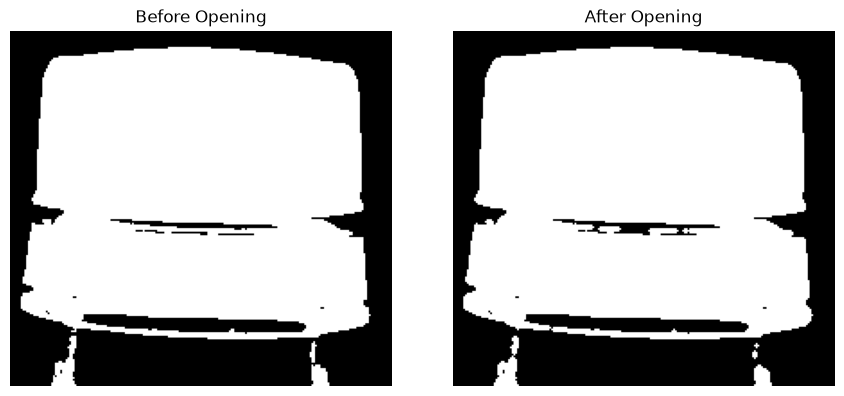

In [23]:
### STEP 23: Otsu vs Opening
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(binary, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Before Opening")
axes[1].imshow(opened, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After Opening")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**확인:** 작은 흰색 점이 줄었나요? 병뚜껑의 필요한 경계도 함께 사라지지 않았나요?

## STEP 24. Closing을 1회 적용합니다

In [24]:
### STEP 24: Closing
cleaned = cv2.morphologyEx(
    opened,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=1,
)
print("Closing 결과 Shape:", cleaned.shape)

Closing 결과 Shape: (198, 213)


Closing은 작은 **검정 구멍을 메우거나 가까운 흰색 영역을 연결**하는 데 사용합니다. `opened`를 입력으로 사용하기 때문에 **Opening → Closing의 순서**를 유지합니다.

## STEP 25. 세 결과를 한눈에 비교합니다

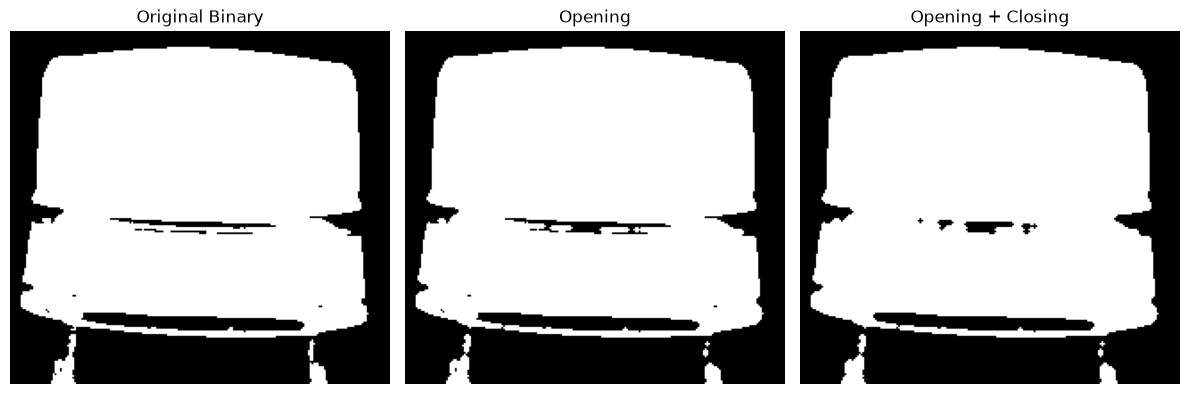

In [25]:
### STEP 25: Binary → Opening → Closing
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, view, title in zip(
    axes,
    [binary, opened, cleaned],
    ["Original Binary", "Opening", "Opening + Closing"],
):
    ax.imshow(view, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**다음 단계 연결:** 이제 `cleaned`는 잡음을 정리한 Binary 이미지이며, **Contour 검출 함수에 입력**됩니다.

## STEP 26. 실제로 몇 픽셀이 달라졌는지 확인합니다(Jupyter 추가)

In [26]:
### STEP 26: 각 단계에서 변경된 픽셀 수
print("Opening 변경 픽셀:", np.count_nonzero(binary != opened))
print("Closing 변경 픽셀:", np.count_nonzero(opened != cleaned))

Opening 변경 픽셀: 84
Closing 변경 픽셀: 158


이 수치는 **변경된 픽셀 개수**이지 정답률이나 개선율이 아닙니다. 변한 픽셀이 많다고 무조건 좋은 전처리는 아닙니다.

---

# BLOCK 5 — Contour를 찾아 Area Ratio 계산(Feature Measurement)

> 이 블록이 3일차의 핵심입니다. 사람 눈에 보이던 검은 병뚜껑 영역을 **비교 가능한 숫자(Feature)** 로 바꿉니다.

## STEP 27. 정리된 Binary에서 Contour를 찾습니다

In [27]:
### BLOCK 5 — Contour와 면적 비율
### STEP 27: 외곽선 찾기
contours, _ = cv2.findContours(
    cleaned.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE,
)
print("검출한 Contour 수:", len(contours))

검출한 Contour 수: 5


`RETR_EXTERNAL`은 **바깥쪽 Contour**를 검출합니다. `CHAIN_APPROX_SIMPLE`은 외곽선 좌표를 일부 압축하여 저장합니다. Contour는 단순히 흰색 픽셀 목록이 아니라 **영역의 외곽 경계를 표현하는 좌표 집합**입니다.

## STEP 28. 검출된 Contour의 면적을 하나씩 확인합니다

In [28]:
### STEP 28: 모든 Contour 면적
contour_areas = [cv2.contourArea(c) for c in contours]
print("검출 면적 목록:", [round(a, 1) for a in contour_areas])

검출 면적 목록: [75.5, 6.0, 2.0, 159.5, 27878.0]


작은 Noise도 Contour로 검출될 수 있습니다. 따라서 이후에 **너무 작은 면적을 제외**합니다.

## STEP 29. ROI 이미지의 가로·세로 크기를 구합니다

In [29]:
### STEP 29: ROI 크기
height, width = image.shape[:2]
print("Height:", height)
print("Width :", width)

Height: 198
Width : 213


이미 ROI 이미지이므로 `width × height`는 **검사 ROI 전체의 픽셀 면적**입니다.

## STEP 30. ROI 전체 면적을 계산합니다

In [30]:
### STEP 30: 전체 면적
image_area = float(width * height)
print("ROI 전체 면적:", image_area)

ROI 전체 면적: 42174.0


예를 들어 ROI가 200×200이라면 전체 면적은 40,000입니다. 실제 결과는 제공 이미지의 크기에 따라 달라집니다.

## STEP 31. 제외할 최소 Contour 면적을 계산합니다

In [31]:
### STEP 31: 작은 Contour 제거 기준
min_area = image_area * MIN_CONTOUR_AREA_RATIO
print("유효 Contour 최소 면적:", min_area)

유효 Contour 최소 면적: 42.174


`MIN_CONTOUR_AREA_RATIO = 0.001`이므로 ROI 전체 면적의 **0.1% 미만**이면 제외됩니다.

## STEP 32. 면적 조건이 만족되는지 Contour별로 확인합니다

In [32]:
### STEP 32: 필터를 적용하기 전 조건 확인
for i, contour in enumerate(contours):
    area = cv2.contourArea(contour)
    print(f"Contour {i}: area={area:.1f}, 유효={area >= min_area}")

Contour 0: area=75.5, 유효=True
Contour 1: area=6.0, 유효=False
Contour 2: area=2.0, 유효=False
Contour 3: area=159.5, 유효=True
Contour 4: area=27878.0, 유효=True


어떤 Contour가 `True`인지 직접 확인합니다. 여러 줄을 화면에 표시하는 `for`문은 **한 Code Cell** 안에 둡니다.

## STEP 33. 유효한 Contour만 남깁니다

In [33]:
### STEP 33: 유효 Contour 필터링
valid = [
    contour
    for contour in contours
    if cv2.contourArea(contour) >= min_area
]
print("필터링 전 Contour:", len(contours))
print("필터링 후 Contour:", len(valid))

필터링 전 Contour: 5
필터링 후 Contour: 3


이것이 원본의 **List Comprehension(리스트 컴프리헨션)** 입니다. 조건을 만족하는 Contour만 `valid`에 저장합니다.

## STEP 34. 유효한 Contour가 없는 경우를 먼저 확인합니다

In [34]:
### STEP 34: 데이터 검증(Jupyter 안전장치)
print("유효 Contour 존재:", bool(valid))
if not valid:
    raise RuntimeError(
        "유효 Contour가 없습니다. 원본 함수는 이 경우 (0.0, image, None)을 반환합니다."
    )

유효 Contour 존재: True


**원본과의 차이:** 실제 `measure_area_ratio()` 함수는 유효 Contour가 없으면 **`(0.0, image, None)`** 을 반환합니다. Jupyter에서 계산을 하나씩 수행할 때는 다음 `max()` 단계의 오류를 막고 원인을 확인할 수 있게 설명용 중단 검사를 추가했습니다.

## STEP 35. 가장 큰 Contour를 선택합니다

In [35]:
### STEP 35: 가장 면적이 큰 Contour
largest = max(valid, key=cv2.contourArea)
print("선택한 Contour Shape:", largest.shape)

선택한 Contour Shape: (184, 1, 2)


여기서 선택한 `largest`는 **가장 큰 Contour 하나**입니다. 작은 영역까지 모두 합친 면적을 구하는 것이 아닙니다.

## STEP 36. 선택한 Contour의 면적을 계산합니다

In [36]:
### STEP 36: 가장 큰 외곽선의 면적
largest_area = float(cv2.contourArea(largest))
print("가장 큰 Contour 면적:", largest_area)

가장 큰 Contour 면적: 27878.0


`cv2.contourArea()`는 외곽선 좌표로 둘러싸인 면적을 계산합니다. **흰 픽셀의 개수를 단순히 모두 더한 값과 정확히 같지 않을 수 있습니다.**

## STEP 37. Area Ratio를 계산합니다

In [37]:
### STEP 37: 가장 중요한 Feature
area_ratio = largest_area / image_area if image_area > 0 else 0.0
print("Area Ratio:", area_ratio)
print("ROI 대비 면적 비율(%):", area_ratio * 100)

Area Ratio: 0.6610233793332385
ROI 대비 면적 비율(%): 66.10233793332385


**Area Ratio = 가장 큰 Contour의 면적 ÷ ROI 전체 면적.** 예를 들어 `0.45`라면 ROI 전체에서 해당 Contour가 차지하는 면적 비율이 약 **45%**라는 뜻입니다. **Accuracy(정확도)나 Confidence(신뢰도)가 아닙니다.**

## STEP 38. 흰 픽셀 수와 Contour 면적이 같은지 비교해 봅니다(Jupyter 추가)

In [38]:
### STEP 38: 다른 면적 개념 비교
white_pixel_count = int(np.count_nonzero(cleaned == 255))
print("Binary 전체 흰 픽셀 수:", white_pixel_count)
print("선택한 Contour 면적:", largest_area)
print("두 값이 정확히 같은가?:", white_pixel_count == largest_area)

Binary 전체 흰 픽셀 수: 27498
선택한 Contour 면적: 27878.0
두 값이 정확히 같은가?: False


흰 픽셀 개수는 **이미지 전체의 255 픽셀 수**이고, `largest_area`는 **선택된 하나의 Contour로 계산한 면적**입니다. 같은 의미로 혼동하지 않습니다.

## STEP 39. 선택한 Contour를 녹색으로 표시합니다

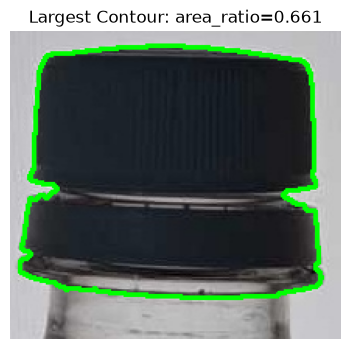

In [39]:
### STEP 39: 원본 보존 후 녹색 Contour 표시
contour_preview = image.copy()
cv2.drawContours(contour_preview, [largest], -1, (0, 255, 0), 2)
plt.figure(figsize=(5, 4))
plt.imshow(cv2.cvtColor(contour_preview, cv2.COLOR_BGR2RGB))
plt.title(f"Largest Contour: area_ratio={area_ratio:.3f}")
plt.axis("off")
plt.show()

녹색 선은 **선택된 객체의 외곽선**, 제목의 소수는 **그 외곽선으로 계산한 면적 비율**입니다. `image.copy()`를 사용하므로 원본 배열은 보존됩니다.

---

# BLOCK 6 — 함수를 완성하고 정상·불량을 같은 방식으로 측정(Function + Compare)

> 지금까지 직접 실습한 `이미지 읽기 → Gray → Otsu → Morphology → Contour → Area Ratio`를 **재사용 가능한 함수**로 묶습니다. 함수 정의는 Python 문법상 전체가 하나의 셀이어야 합니다. 아래 코드는 **사용자가 제공한 원본 `21_cap_rule.py`의 측정 로직을 그대로 유지**합니다.

## STEP 40. `measure_area_ratio()` 함수를 정의합니다

In [40]:
### BLOCK 6 — 함수 정의
### STEP 40: 앞서 검증한 내용을 하나의 함수로 통합
def measure_area_ratio(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(
            f"이미지를 읽지 못했습니다: {image_path}"
        )

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    _, binary = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU,
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    opened = cv2.morphologyEx(
        binary, cv2.MORPH_OPEN, kernel, iterations=1
    )

    cleaned = cv2.morphologyEx(
        opened, cv2.MORPH_CLOSE, kernel, iterations=1
    )

    contours, _ = cv2.findContours(
        cleaned.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    height, width = image.shape[:2]
    image_area = float(width * height)
    min_area = image_area * MIN_CONTOUR_AREA_RATIO

    valid = [
        contour
        for contour in contours
        if cv2.contourArea(contour) >= min_area
    ]

    if not valid:
        return (0.0, image, None)

    largest = max(valid, key=cv2.contourArea)
    largest_area = float(cv2.contourArea(largest))
    area_ratio = (
        largest_area / image_area if image_area > 0 else 0.0
    )

    return (area_ratio, image, largest)

print("measure_area_ratio() 함수 정의 완료")

measure_area_ratio() 함수 정의 완료


**함수 입력과 출력**

```text
입력: image_path
  → 이미지 경로 1개

출력: (area_ratio, image, largest)
  → area_ratio: 숫자로 계산한 면적 비율
  → image: 원본 BGR 배열
  → largest: 가장 큰 Contour 또는 None
```

## STEP 41. 함수 계산값과 앞에서 직접 계산한 값을 비교합니다

In [41]:
### STEP 41: 단계별 계산 vs 함수 계산
ratio_from_function, image_from_function, contour_from_function = (
    measure_area_ratio(CAP_ON_PATH)
)
print("단계별 Area Ratio:", area_ratio)
print("함수 Area Ratio:", ratio_from_function)
print("일치 여부:", np.isclose(area_ratio, ratio_from_function))

단계별 Area Ratio: 0.6610233793332385
함수 Area Ratio: 0.6610233793332385
일치 여부: True


위 두 결과는 **같은 이미지·같은 파라미터**라면 일치해야 합니다. `False`라면 중간 단계에서 변수나 Kernel 설정을 잘못 바꾸었는지 확인합니다.

## STEP 42. 병뚜껑이 있는 Reference를 함수로 측정합니다

In [42]:
### STEP 42: cap_on 기준값 측정
cap_on_ratio, _, _ = measure_area_ratio(CAP_ON_PATH)
print("cap_on_ratio:", cap_on_ratio)

cap_on_ratio: 0.6610233793332385


여기서의 `_`는 **반환된 이미지와 Contour를 이 단계에서는 사용하지 않겠다는 뜻**입니다.

## STEP 43. 병뚜껑이 없는 Reference도 같은 함수로 측정합니다

In [43]:
### STEP 43: cap_off 기준값 측정
cap_off_ratio, _, _ = measure_area_ratio(CAP_OFF_PATH)
print("cap_off_ratio:", cap_off_ratio)

cap_off_ratio: 0.45874235310855027


`cap_on`과 `cap_off`에 **동일한 전처리·Contour 면적 측정 방식**을 적용합니다.

## STEP 44. 정상·불량의 Area Ratio를 나란히 출력합니다

In [44]:
### STEP 44: 두 측정값 비교
print("cap_on  면적 비율:", cap_on_ratio)
print("cap_off 면적 비율:", cap_off_ratio)
print("cap_on이 더 큰가?:", cap_on_ratio > cap_off_ratio)

cap_on  면적 비율: 0.6610233793332385
cap_off 면적 비율: 0.45874235310855027
cap_on이 더 큰가?: True


실제 이미지에 따라 숫자는 달라집니다. 먼저 두 값을 **측정하고** 어느 쪽이 더 큰지 판단해야 합니다.

## STEP 45. 두 비율을 그래프로 비교합니다(Jupyter 추가)

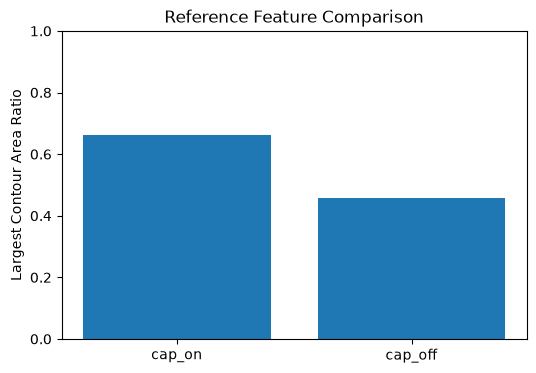

In [45]:
### STEP 45: Reference Area Ratio 막대그래프
plt.figure(figsize=(6, 4))
plt.bar(["cap_on", "cap_off"], [cap_on_ratio, cap_off_ratio])
plt.ylim(0, 1)
plt.ylabel("Largest Contour Area Ratio")
plt.title("Reference Feature Comparison")
plt.show()

막대의 높이는 **병뚜껑 유무에 따른 Area Ratio 차이**입니다. 이미지가 달라져도 항상 같은 값이 나오는 것은 아닙니다.

---

# BLOCK 7 — 측정값으로 기준을 만들고 OK / NG 판정하기(Rule)

## STEP 46. 두 Reference 측정값의 차이를 계산합니다

In [46]:
### BLOCK 7 — Rule 생성과 판정
### STEP 46: Reference Gap
reference_gap = abs(cap_on_ratio - cap_off_ratio)
print("reference gap:", reference_gap)

reference gap: 0.20228102622468824


두 기준 이미지에서 Feature 값이 **얼마나 떨어져 있는지** 보여줍니다. Gap이 작으면 현재 Area Ratio 하나로 구분하기 어려울 수 있습니다.

## STEP 47. 두 측정값의 중간을 후보 기준값으로 정합니다

In [47]:
### STEP 47: 중간값을 후보 기준으로 선택
candidate_threshold = (cap_on_ratio + cap_off_ratio) / 2.0
print("candidate threshold:", candidate_threshold)

candidate threshold: 0.5598828662208943


예를 들어 `cap_on=0.66`, `cap_off=0.46`이라면 중간값은 약 `0.56`입니다. 이 값은 Otsu가 고른 픽셀 임계값이 아니라 **Area Ratio 판정 기준값**입니다.

## STEP 48. 비교 방향을 정합니다

In [48]:
### STEP 48: cap_on일 때 비율이 더 큰가?
cap_present_when_greater = cap_on_ratio > cap_off_ratio
print("cap present when greater:", cap_present_when_greater)

cap present when greater: True


`True`면 **면적 비율이 큰 쪽이 cap_on**, `False`면 **작거나 같은 쪽이 cap_on**으로 판단하도록 원본 코드가 구성되어 있습니다. 단, 두 값이 완전히 같다면 이 Feature로 구분할 근거가 없으므로 판정을 신뢰해서는 안 됩니다.

## STEP 49. 후보 기준값과 Gap이 적절한지 점검합니다(Jupyter 추가)

In [49]:
### STEP 49: 기준값 QA
print("cap_on / cap_off 값이 동일한가?:", np.isclose(cap_on_ratio, cap_off_ratio))
print("후보 기준값:", candidate_threshold)
if np.isclose(cap_on_ratio, cap_off_ratio):
    print("주의: 두 값이 거의 같으므로 다른 Feature나 촬영 조건을 검토하세요.")

cap_on / cap_off 값이 동일한가?: False
후보 기준값: 0.5598828662208943


이 셀은 **잘못된 기준값을 무조건 정답으로 받아들이지 않기 위한 학습용 추가 검사**입니다. 원본 21번은 기준값의 품질을 자동으로 검증하지 않습니다.

## STEP 50. `judge_cap()` 판정 함수를 정의합니다

In [50]:
### STEP 50: 원본의 판정 함수
def judge_cap(area_ratio):
    if cap_present_when_greater:
        cap_present = area_ratio >= candidate_threshold
    else:
        cap_present = area_ratio <= candidate_threshold

    if cap_present:
        return ("OK", "")

    return ("NG", "NG_CAP_AREA")

print("judge_cap() 함수 정의 완료")

judge_cap() 함수 정의 완료


**입력:** Area Ratio 숫자 한 개. **출력:** `(판정, 이유)` 두 문자열입니다. `""`는 OK일 때 추가 NG 사유가 없다는 뜻이고, `"NG_CAP_AREA"`는 **면적 비율 기준을 만족하지 못해 NG**가 됐다는 의미입니다.

## STEP 51. 첫 기준 이미지를 함수에 넣어 판정합니다

In [51]:
### STEP 51: cap_on 기준 이미지 판정
on_decision, on_reason = judge_cap(cap_on_ratio)
print("cap_on 판정:", on_decision)
print("cap_on 이유:", repr(on_reason))

cap_on 판정: OK
cap_on 이유: ''


기준 이미지에서 만든 Rule이므로 보통 `OK`가 나옵니다. **하지만 기준 이미지에 다시 적용한 결과는 독립적인 테스트 정확도가 아닙니다.**

## STEP 52. 두 번째 기준 이미지도 판정합니다

In [52]:
### STEP 52: cap_off 기준 이미지 판정
off_decision, off_reason = judge_cap(cap_off_ratio)
print("cap_off 판정:", off_decision)
print("cap_off 이유:", off_reason)

cap_off 판정: NG
cap_off 이유: NG_CAP_AREA


기준값이 정상적으로 두 값을 구분했다면 `NG`와 `NG_CAP_AREA`가 출력됩니다.

## STEP 53. 후보값 근처의 가상 측정값으로 조건문을 검증합니다(Jupyter 추가)

In [53]:
### STEP 53: Threshold 바로 아래·같음·바로 위
for test_ratio in [
    candidate_threshold - 0.01,
    candidate_threshold,
    candidate_threshold + 0.01,
]:
    decision, reason = judge_cap(test_ratio)
    print(f"입력={test_ratio:.4f} → {decision}, reason={reason!r}")

입력=0.5499 → NG, reason='NG_CAP_AREA'
입력=0.5599 → OK, reason=''
입력=0.5699 → OK, reason=''


**중요:** 이 셀의 세 숫자는 새 이미지로 실제 측정한 데이터가 아니라, 조건문의 비교 방향을 확인하기 위한 **가상 입력값**입니다. `>=` 또는 `<=`에서 **기준값과 정확히 같을 때** 어느 쪽으로 판정하는지도 확인합니다.

## STEP 54. 원본 코드처럼 기준값과 판정 방향을 출력합니다

In [54]:
### STEP 54: 원본의 요약 출력
print("cap_on ratio :", cap_on_ratio)
print("cap_off ratio:", cap_off_ratio)
print("reference gap:", abs(cap_on_ratio - cap_off_ratio))
print("candidate threshold:", candidate_threshold)
print("cap present when:", "GREATER" if cap_present_when_greater else "LESS")

cap_on ratio : 0.6610233793332385
cap_off ratio: 0.45874235310855027
reference gap: 0.20228102622468824
candidate threshold: 0.5598828662208943
cap present when: GREATER


다음과 비슷한 구조로 표시됩니다. **숫자는 각자의 이미지에 따라 달라집니다.**

```text
cap_on ratio : (실제 측정값)
cap_off ratio: (실제 측정값)
reference gap: (두 값의 차이)
candidate threshold: (두 값의 중간값)
cap present when: GREATER 또는 LESS
```

---

# BLOCK 8 — Contour와 OK / NG를 결과 이미지에 표시하고 저장하기(Output)

## STEP 55. 첫 번째 결과 이미지를 다시 읽어 측정합니다

In [55]:
### BLOCK 8 — 시각화와 파일 저장
### STEP 55: 첫 이미지 계산
area_ratio_on, image_on, contour_on = measure_area_ratio(CAP_ON_PATH)
print("측정 비율:", area_ratio_on)
print("Contour 존재:", contour_on is not None)

측정 비율: 0.6610233793332385
Contour 존재: True


이미지에 녹색 선을 그리려면 반환된 **Contour 좌표**가 필요합니다. 따라서 두 번째와 세 번째 반환값도 받습니다.

## STEP 56. 첫 번째 이미지의 판정을 구합니다

In [56]:
### STEP 56: OK / NG 문자열 얻기
decision_on, reason_on = judge_cap(area_ratio_on)
print("결정:", decision_on)
print("사유:", repr(reason_on))

결정: OK
사유: ''


이제 숫자 `area_ratio_on`이 사람에게 읽기 쉬운 `"OK"` 또는 `"NG"`로 변환되었습니다.

## STEP 57. 원본 이미지를 복사합니다

In [57]:
### STEP 57: 원본 데이터 보존
result_on = image_on.copy()
print("결과 이미지 Shape:", result_on.shape)

결과 이미지 Shape: (198, 213, 3)


앞에서 배운 1일차 ROI Preview와 마찬가지로, 선과 글씨를 직접 원본 배열에 덮어 그리지 않도록 **복사본**을 만듭니다.

## STEP 58. Contour가 있다면 녹색으로 표시합니다

In [58]:
### STEP 58: 외곽선 시각화
if contour_on is not None:
    cv2.drawContours(result_on, [contour_on], -1, (0, 255, 0), 2)
print("Contour 표시 완료")

Contour 표시 완료


BGR의 `(0, 255, 0)`은 녹색, 마지막 `2`는 선 두께입니다. Contour가 없으면 선을 그리지 않습니다.

## STEP 59. 이미지에 표시할 문자열을 만듭니다

In [59]:
### STEP 59: 라벨 문자열 준비
text_on = f"{decision_on} ratio={area_ratio_on:.3f}"
print("표시할 글자:", text_on)

표시할 글자: OK ratio=0.661


예: `OK ratio=0.661`. `.3f`는 소수점 이하 세 자리로 **표시**하며 원래 숫자의 정밀도를 바꾸지는 않습니다.

## STEP 60. OK 또는 NG에 따라 글자 색을 정합니다

In [60]:
### STEP 60: 판정별 BGR 색상
text_color_on = (0, 200, 0) if decision_on == "OK" else (0, 0, 255)
print("글자 색상(BGR):", text_color_on)

글자 색상(BGR): (0, 200, 0)


OK는 녹색 계열, NG는 빨간색으로 표시합니다. 이 색상은 **결과 화면을 읽기 쉽게 하는 시각화 옵션**입니다.

## STEP 61. 이미지 위에 글자를 표시합니다

In [61]:
### STEP 61: cv2.putText 실행
cv2.putText(
    result_on, text_on, (10, 30),
    cv2.FONT_HERSHEY_SIMPLEX, 0.65,
    text_color_on, 2,
)
print("판정 글자 표시 완료")

판정 글자 표시 완료


`(10, 30)`은 글자가 시작되는 화면 좌표이며, 글자 크기나 색상은 측정·판정 계산값에 영향을 주지 않습니다.

## STEP 62. 완성된 첫 번째 이미지를 화면에서 봅니다

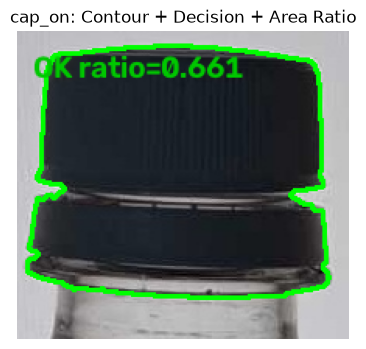

In [62]:
### STEP 62: 결과 Preview
plt.figure(figsize=(5, 4))
plt.imshow(cv2.cvtColor(result_on, cv2.COLOR_BGR2RGB))
plt.title("cap_on: Contour + Decision + Area Ratio")
plt.axis("off")
plt.show()

**확인 질문:** 녹색 Contour가 병뚜껑 영역을 둘러싸나요? 상단의 `OK ratio=...`가 21번의 판정 결과와 일치하나요?

## STEP 63. 결과 이미지 한 장을 저장합니다

In [63]:
### STEP 63: 첫 결과 저장
on_output_path = OUTPUT_DIR / "cap_on_rule.jpg"
saved_on = cv2.imwrite(str(on_output_path), result_on)
print("저장 성공:", saved_on)
print("파일 경로:", on_output_path)

저장 성공: True
파일 경로: outputs/day03/rule/cap_on_rule.jpg


`cv2.imwrite()`는 저장 성공 여부를 `True`/`False`로 반환합니다. **RGB 변환 배열이 아닌 OpenCV BGR 배열인 `result_on`을 저장**합니다.

## STEP 64. 원본 프로그램의 반복문으로 두 장을 모두 처리합니다

> 앞에서 한 장씩 검증한 **측정 → 판정 → 원본 복사 → Contour 표시 → 글씨 표시 → 저장**을 이제 두 파일에 반복합니다. `for`문 전체는 문법상 **하나의 Jupyter Code Cell**에 있어야 합니다. 이 코드는 사용자가 제공한 원본 21번의 최종 실행 흐름을 그대로 유지합니다.

In [64]:
### STEP 64: 원본의 최종 반복 처리
for label, image_path in [
    ("cap_on", CAP_ON_PATH),
    ("cap_off", CAP_OFF_PATH),
]:
    area_ratio, image, contour = measure_area_ratio(image_path)
    decision, reason = judge_cap(area_ratio)
    result = image.copy()

    if contour is not None:
        cv2.drawContours(result, [contour], -1, (0, 255, 0), 2)

    text = f"{decision} ratio={area_ratio:.3f}"

    cv2.putText(
        result,
        text,
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (0, 200, 0) if decision == "OK" else (0, 0, 255),
        2,
    )

    output_path = OUTPUT_DIR / f"{label}_rule.jpg"
    cv2.imwrite(str(output_path), result)

    print()
    print("file:", image_path.name)
    print("area_ratio:", area_ratio)
    print("decision:", decision)
    print("reason:", reason)


file: cap_on.jpg
area_ratio: 0.6610233793332385
decision: OK
reason: 

file: cap_off.jpg
area_ratio: 0.45874235310855027
decision: NG
reason: NG_CAP_AREA


**읽는 순서:** `label`(파일 역할) → `measure_area_ratio()`(수치 측정) → `judge_cap()`(판정) → `drawContours()`(외곽선 표시) → `putText()`(결과 표시) → `imwrite()`(저장). 이 셀을 실행하면 `cap_on_rule.jpg`를 다시 저장하고 `cap_off_rule.jpg`도 생성합니다.

## STEP 65. 두 결과 파일이 실제 생성되었는지 확인합니다

In [65]:
### STEP 65: 출력 QA
on_path = OUTPUT_DIR / "cap_on_rule.jpg"
off_path = OUTPUT_DIR / "cap_off_rule.jpg"
print("ON  결과 존재:", on_path.is_file())
print("OFF 결과 존재:", off_path.is_file())
if not (on_path.is_file() and off_path.is_file()):
    raise IOError("결과 파일 중 일부가 생성되지 않았습니다.")

ON  결과 존재: True
OFF 결과 존재: True


둘 다 `True`라면 파일을 만들었습니다. 이제 실제 내용을 읽어 확인합니다.

## STEP 66. 저장한 결과 이미지를 다시 읽습니다

In [66]:
### STEP 66: 저장 파일 재로드
saved_on_image = cv2.imread(str(on_path))
saved_off_image = cv2.imread(str(off_path))
if saved_on_image is None or saved_off_image is None:
    raise IOError("저장한 결과 이미지를 다시 읽지 못했습니다.")
print("ON  Shape:", saved_on_image.shape)
print("OFF Shape:", saved_off_image.shape)

ON  Shape: (198, 213, 3)
OFF Shape: (198, 213, 3)


저장 성공 메시지만 확인하는 것보다 **다시 읽어 실제 이미지가 정상적인지 검증**하는 습관이 중요합니다.

## STEP 67. OK / NG 이미지를 나란히 비교합니다

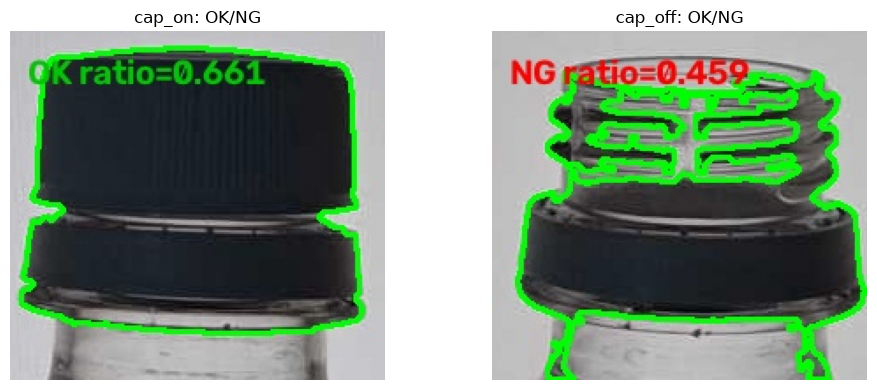

In [67]:
### STEP 67: 최종 결과 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, view, title in zip(
    axes,
    [saved_on_image, saved_off_image],
    ["cap_on: OK/NG", "cap_off: OK/NG"],
):
    ax.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**최종 확인:** 녹색 Contour와 숫자(`ratio=...`), 판정(`OK` / `NG`)이 실제 입력 이미지의 상태와 일치하는지 살펴봅니다. Jupyter에서 본 결과와 디스크에 저장된 결과가 같아야 합니다.

---

# BLOCK 9 — 원본 `.py`와 연결·재현하기(Integration + Mini Challenge)

## STEP 68. Jupyter 리뷰와 원본 `.py`의 관계를 확인합니다

| 구분 | 원본 `21_cap_rule.py` | Jupyter 블록별 리뷰 |
|---|---|---|
| 입력 경로·출력 경로 | 두 기준 ROI 지정 | 존재 여부·작업 폴더부터 확인 |
| Gray · Otsu · Morphology | 함수 내부에서 연속 실행 | 각 결과 이미지와 픽셀값을 직접 확인 |
| Contour | `findContours()` 실행 | 개수·면적 목록·유효 조건을 별도 확인 |
| Area Ratio | 가장 큰 Contour 면적 / ROI 면적 | 계산값과 백분율을 함께 검증 |
| 정상·불량 비교 | 두 비율 출력 | 그래프로 차이를 확인 |
| 기준값 생성 | 두 값의 중간값 | Gap·비교 방향을 단계별 확인 |
| Rule | `judge_cap()` | 기준값 전후 가상 수치로 비교 연습 |
| 결과 | 두 장의 이미지 저장 | 저장 성공·재로드·나란히 확인 |

**중요:** Jupyter에서 `MIN_CONTOUR_AREA_RATIO`, Kernel 크기 또는 판정 기준값을 바꿔도 `src/21_cap_rule.py` 원본 파일에 **자동 반영되지는 않습니다.** 실험에서 실제로 선택한 설정을 원본 코드에 직접 수정해야 동일한 결과를 재현할 수 있습니다.

## STEP 69. 현재 판정 기준과 결과를 한눈에 확인합니다

In [68]:
### STEP 69: 학습 결과 정리
print("cap_on ratio :", cap_on_ratio)
print("cap_off ratio:", cap_off_ratio)
print("reference gap:", abs(cap_on_ratio - cap_off_ratio))
print("candidate threshold:", candidate_threshold)
print("판정 방향:", "GREATER" if cap_present_when_greater else "LESS")
print("cap_on  판정:", judge_cap(cap_on_ratio))
print("cap_off 판정:", judge_cap(cap_off_ratio))

cap_on ratio : 0.6610233793332385
cap_off ratio: 0.45874235310855027
reference gap: 0.20228102622468824
candidate threshold: 0.5598828662208943
판정 방향: GREATER
cap_on  판정: ('OK', '')
cap_off 판정: ('NG', 'NG_CAP_AREA')


여기까지의 검사는 **기준 이미지 2장에 기반한 후보 Rule의 동작 확인**입니다. 별도 이미지로 성능을 평가한 것이 아니므로 **Accuracy 100%라고 주장하면 안 됩니다.**

## STEP 70. 원본 `21_cap_rule.py`를 터미널에서 실행합니다

프로젝트 최상위 터미널에서 실행합니다.

```bash
python src/21_cap_rule.py
```

또는 Jupyter에서 아래 셀을 **선택적으로** 실행할 수 있습니다.

In [69]:
### STEP 70: 기존 .py 통합 실행(선택)
import sys
import subprocess
subprocess.run([sys.executable, "src/21_cap_rule.py"], check=True)

cap_on ratio : 0.6610233793332385
cap_off ratio: 0.45874235310855027
reference gap: 0.20228102622468824
candidate threshold: 0.5598828662208943
cap present when: GREATER

file: cap_on.jpg
area_ratio: 0.6610233793332385
decision: OK
reason: 

file: cap_off.jpg
area_ratio: 0.45874235310855027
decision: NG
reason: NG_CAP_AREA


CompletedProcess(args=['/home/user1/ai_vision/subject9_machinevision/.venv/bin/python', 'src/21_cap_rule.py'], returncode=0)

원본 Python 파일이 실제 `src/21_cap_rule.py`에 존재해야 합니다. 원본과 Jupyter는 **같은 `outputs/day03/rule/`에 저장**하므로 결과 이미지가 덮어써질 수 있습니다.

## STEP 71. 핵심 코드 리뷰 질문

1. 3일차는 이미 ROI로 잘린 이미지를 왜 다시 Crop하지 않나요?
2. `cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)`로 바뀌는 것은 무엇인가요?
3. `THRESH_BINARY_INV`에서는 어두운 병뚜껑 픽셀이 왜 255로 표시되나요?
4. Opening과 Closing의 역할은 각각 무엇인가요?
5. `cv2.findContours()`의 반환값인 `contours`에는 어떤 데이터가 들어 있나요?
6. `MIN_CONTOUR_AREA_RATIO = 0.001`은 OK/NG 기준값인가요?
7. `largest_area`와 `image_area`는 어떤 차이가 있나요?
8. `area_ratio = 0.45`는 45% 면적 비율인가요, 45% 정확도인가요?
9. `cap_on_ratio`, `cap_off_ratio`를 비교하는 이유는 무엇인가요?
10. Otsu 임계값과 `candidate_threshold`는 같은 종류의 값인가요?
11. `cap_present_when_greater`가 `False`이면 판정 조건이 어떻게 달라지나요?
12. `judge_cap()`이 반환하는 `("NG", "NG_CAP_AREA")`는 무엇을 뜻하나요?
13. `image.copy()` 없이 이미지에 Contour·문자를 직접 그리면 어떤 점을 주의해야 하나요?
14. 기준 이미지 두 장에서 OK/NG가 잘 나왔다고 성능이 검증된 것인가요?
15. 새로운 이미지에서 실제 판정 능력은 어느 파일에서 검사하나요? (힌트: `22_cap_batch_test.py`)

## STEP 72. 직접 바꾸어 보는 작은 Jupyter Challenge

| 실험 | 바꾸는 위치 | 확인할 결과 | 주의 |
|---|---|---|---|
| A — Kernel 비교 | STEP 40 함수 내부 `(3, 3)`을 `(5, 5)`로 변경 | Contour·Area Ratio 변화 | STEP 40부터 판정과 저장까지 다시 실행 |
| B — Noise 기준 | STEP 7의 `0.001` → `0.01` | 유효 Contour 수·면적 변화 | 너무 높으면 실제 객체가 제외될 수 있음 |
| C — 임계값 근처 | STEP 53의 `±0.01` → `±0.001` | `>=` 또는 `<=` 비교 결과 | 가상 입력값 실험이며 새로운 이미지 검사가 아님 |
| D — 다른 Feature 생각하기 | Contour 수·BBox 크기와 비교 | Area Ratio만 사용할 때의 한계 | 이번 21번의 원본 Rule은 Area Ratio 하나만 사용 |

**실험 순서:** 먼저 원본 설정으로 결과를 저장합니다. A/B 실험 후에는 변경한 함수·변수를 다시 계산해 이전 `cap_on_ratio`, `cap_off_ratio`, `candidate_threshold`를 그대로 사용하지 않도록 주의합니다. 마지막에는 원본 설정 `(3, 3)`, `0.001`로 돌아가 Kernel을 재시작하고 전체 셀을 순서대로 실행하세요.

---

## 오늘의 최종 정리 — 3일차의 핵심 사고방식

```text
2일차에서 배운 Binary 원리
        ↓
3일차: 이미 ROI인 cap_on / cap_off 이미지 읽기
        ↓
Gray → Otsu(Binary Inverse)
        ↓
Morphology(Opening → Closing)
        ↓
Contour 검출 → 작은 Contour 제거
        ↓
가장 큰 Contour 선택
        ↓
Area Ratio 수치화
        ↓
cap_on / cap_off 측정값 비교
        ↓
Candidate Threshold 계산
        ↓
judge_cap()로 OK / NG 결정
        ↓
Contour + 결과 문자열 표시·저장
        ↓
다음 `22_cap_batch_test.py`에서 새로운 이미지 4장으로 검증
```

**가장 중요한 학습 성과:** 학생이 `Area Ratio`가 무엇인지 직접 계산하고, **왜 두 측정값의 중간을 기준값으로 만들었는지**, 그리고 **측정값이 기준보다 크거나 작을 때 어떻게 OK/NG가 나오는지** 설명할 수 있으면 됩니다. 원본 코드 전체를 외우기보다 **입력 → 영상처리 → 특징 측정 → 비교 → Rule → 결과 검증**의 연결을 이해하는 것이 중요합니다.

**참고:** `21_cap_rule.py`는 기준 이미지로 후보 Rule을 만들고 그 기준 이미지 자체를 다시 판정하는 실습입니다. 별도 이미지에 적용해 일반화 가능성을 점검하는 과정은 **`22_cap_batch_test.py`**에서 이어집니다.